# 1 — The basic Most Improved race

**In brief**
- **Question:** What does a Most Improved season look like, and can a simple model name the winner from the box score?
- **Answer:** Most leaps show within ten games. The biggest points jump names the winner only 4 times in 15; a choice model on every box-score change, plus team, age and second year, names him 8 times in 15 (5 of 10 in the strict test). Voters reward a large all-round and scoring jump on a team that wins more, and mark down age, jumps that come only from more minutes, and second-year players. The winners it misses crossed a milestone, such as a first 20-point season.
- **Decisions** ([decision log](../docs/DECISIONS.md)): [D22](../docs/DECISIONS.md) (the baseline season), [D23](../docs/DECISIONS.md) (who is a candidate), [D24](../docs/DECISIONS.md) (a choice model with one winner per season), [D25](../docs/DECISIONS.md) (game score as the one-number summary), [D30](../docs/DECISIONS.md) (the penalty λ = 3).
- **Where it fits:** The first version of the race. Segment 3 investigates the cases it gets wrong; segment 4 refines it, one tested decision at a time, and scores it at five points of the season.
- **Dated:** written 13 November 2026 from notebook 10 (now in [archive/](archive/10_mip_leaps.ipynb)), which has every intermediate step.

**The comparison used throughout.** A player's season is compared with his **baseline season**: his most recent earlier season covering at least a third of the games ([D22](../docs/DECISIONS.md)). Injury-shortened seasons are skipped, so a healthy return (Kawhi Leonard after a 9-game season) is not counted as a leap. **Game score** sums up a box-score line in one number: points, rebounds, assists, steals and blocks, less missed shots, turnovers and fouls ([D25](../docs/DECISIONS.md)).

**Data:** every game from 2010-11 to 2025-26 (404,431 player-games, from [notebook 0](0_data.ipynb)); the winners and the real votes from Basketball-Reference, used only to score predictions, never to train.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn.bref import all_mip_voting, attach_player_ids
from unicorn.gamelogs import add_mip_context, mip_candidates
from unicorn.labels import MIP_WINNERS, add_labels, add_star_score
from unicorn.mip import (ABSOLUTE_ALL, AGE, MILESTONES, RELATIVE_ALL, SECOND_YEAR, TEAM, ChoiceModel, bootstrap_weights, choose_l2,
                         out_of_sample_probabilities, summarize, top_k_overlap, top7_vs_votes_chart)
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, SURFACE, apply_style
from unicorn.raw import PROJECT_ROOT

warnings.filterwarnings("ignore")
apply_style()
DATA = PROJECT_ROOT / "data" / "processed"
games = pd.read_parquet(DATA / "player_games.parquet")
ps = pd.read_parquet(DATA / "player_season.parquet")
levels = add_star_score(add_labels(pd.read_parquet(DATA / "player_season_unicorn.parquet")))
print(f"{len(games):,} player-games, {games['season'].min()} → {games['season'].max()}; {len(MIP_WINNERS)} winners from 2011-12")

404,431 player-games, 2010-11 → 2025-26; 15 winners from 2011-12


## 1A — How winners' seasons unfold

Each winner's game score, week by week, against his baseline season. How much of the season's leap was already there in the first 10 games, and did the All-Star break change anything?

In [2]:
win = games.merge(pd.DataFrame([{"season": s, "player_id": p} for s, p in MIP_WINNERS.items()]), on=["season", "player_id"])
asb_week = games[games["after_all_star"]].groupby("season")["week"].min()
rows = []
for (s, pid), d in win.groupby(["season", "player_id"]):
    rows.append({"season": s, "player": d["player_name"].iloc[0], "baseline": d["base_game_score"].iloc[0],
                 "first 10 games": d.head(10)["game_score"].mean(), "season": s, "whole season": d["game_score"].mean(),
                 "before the break": d.loc[~d["after_all_star"], "game_score"].mean(), "after the break": d.loc[d["after_all_star"], "game_score"].mean(),
                 "minutes: baseline": d["base_min"].iloc[0], "minutes: first 10": d.head(10)["min"].mean()})
unfold = pd.DataFrame(rows).sort_values("season").set_index("season")
unfold["share of the leap in the first 10 games"] = (unfold["first 10 games"] - unfold["baseline"]) / (unfold["whole season"] - unfold["baseline"])
unfold["after vs before the break"] = unfold["after the break"] - unfold["before the break"]
print(f"winners with 80%+ of their leap in the first 10 games: {(unfold['share of the leap in the first 10 games'] >= 0.8).sum()} of {len(unfold)}")
unfold[["player", "baseline", "first 10 games", "whole season", "share of the leap in the first 10 games", "after vs before the break",
        "minutes: baseline", "minutes: first 10"]].style.format({"share of the leap in the first 10 games": "{:.0%}"}, precision=1)

winners with 80%+ of their leap in the first 10 games: 9 of 15


,player,baseline,first 10 games,whole season,share of the leap in the first 10 games,after vs before the break,minutes: baseline,minutes: first 10
season,,,,,,,,
2011-12,Ryan Anderson,8.5,14.2,13.0,125%,-0.4,22.2,30.6
2012-13,Paul George,9.6,9.1,13.0,-15%,-0.7,29.6,36.8
2013-14,Goran Dragic,12.5,11.9,15.7,-21%,-1.5,33.5,32.3
2014-15,Jimmy Butler III,11.0,18.5,17.1,122%,-1.2,38.7,39.9
2015-16,CJ McCollum,4.3,12.8,13.5,91%,0.7,15.7,34.7
2016-17,Giannis Antetokounmpo,14.2,19.0,20.4,78%,-1.4,35.3,34.1
2017-18,Victor Oladipo,10.5,16.6,17.5,87%,-2.5,33.2,32.5
2018-19,Pascal Siakam,6.6,10.5,14.0,53%,1.6,20.7,26.9
2019-20,Brandon Ingram,11.8,18.6,16.7,140%,-5.2,33.9,32.4


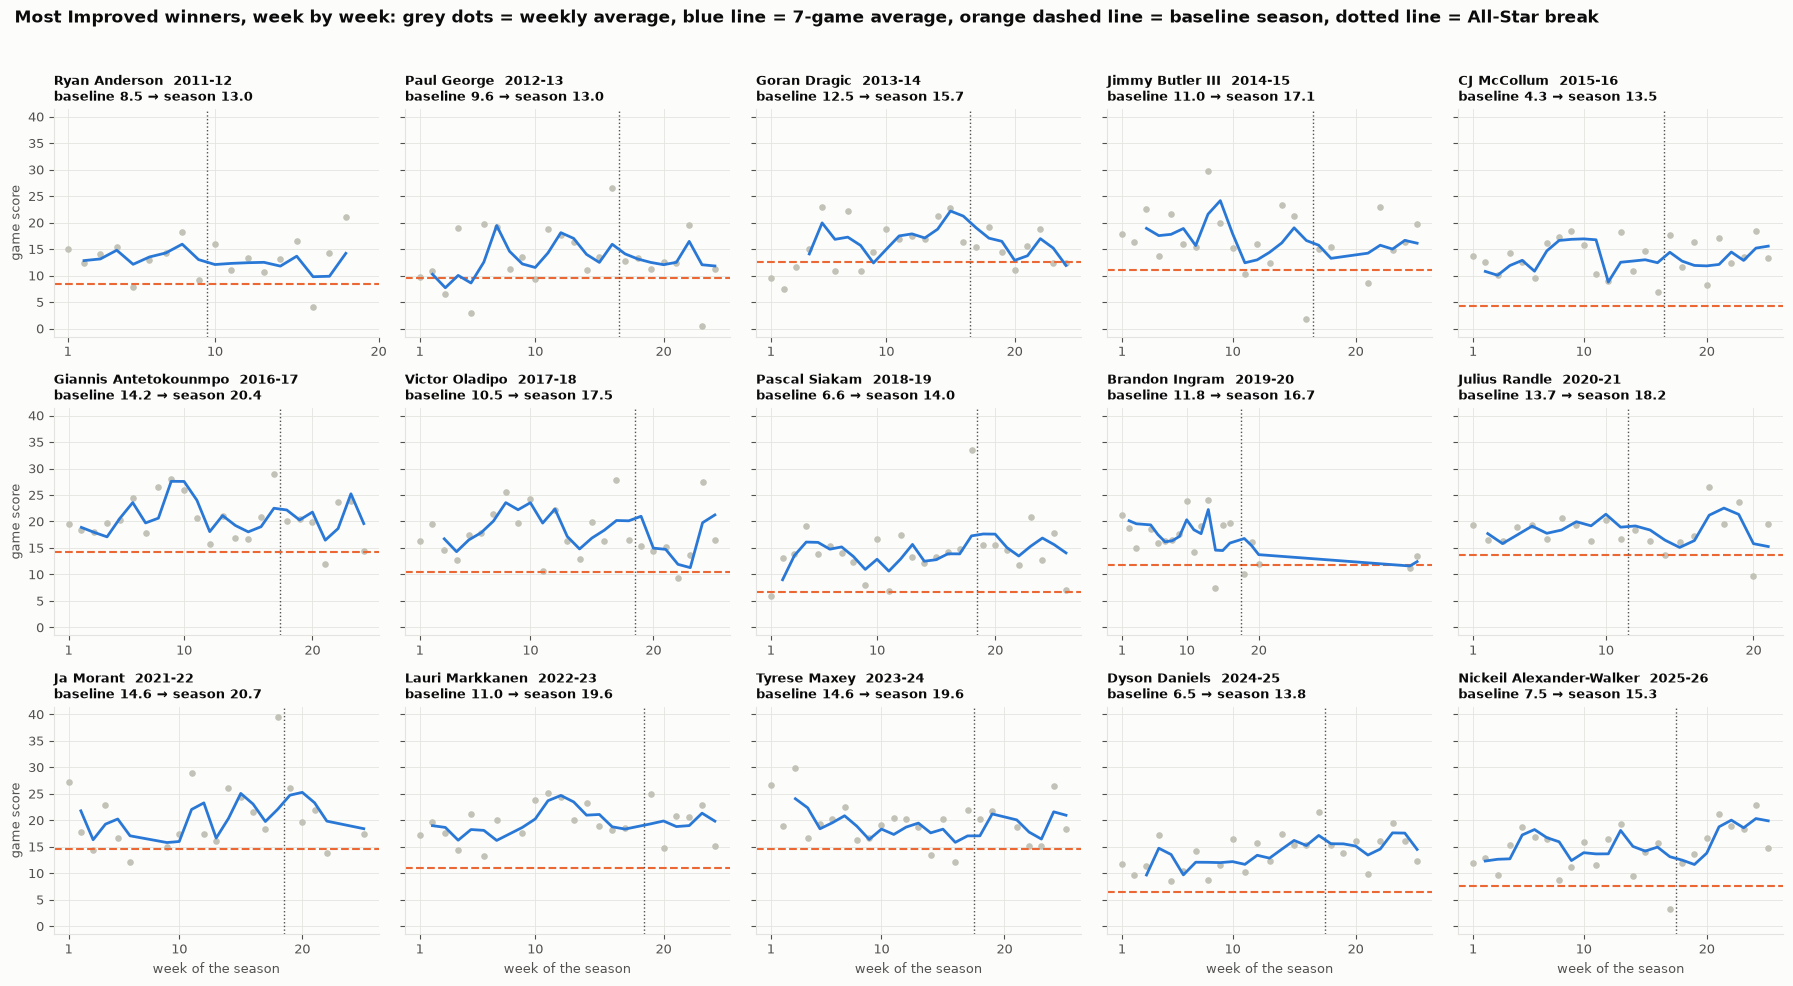

In [3]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10), sharey=True)
for ax, (s, r) in zip(axes.flat, unfold.iterrows()):
    d = win[(win["season"] == s) & (win["player_name"] == r["player"])]
    ax.scatter(d.groupby("week")["game_score"].mean().index, d.groupby("week")["game_score"].mean().values, s=14, color=MUTED, zorder=2)
    roll = d.groupby("week")["game_score_roll7"].last()
    ax.plot(roll.index, roll.values, color=BLUE, linewidth=2, zorder=3)
    ax.axhline(r["baseline"], color=ORANGE, linestyle="--", linewidth=1.5)
    ax.axvline(asb_week[s] - 0.5, color=INK2, linestyle=":", linewidth=1)
    ax.set_title(f"{r['player']}  {s}\nbaseline {r['baseline']:.1f} → season {r['whole season']:.1f}", loc="left", fontsize=9.5)
    ax.set_xticks([1, 10, 20])
for ax in axes[:, 0]:
    ax.set_ylabel("game score")
for ax in axes[-1]:
    ax.set_xlabel("week of the season")
fig.suptitle("Most Improved winners, week by week: grey dots = weekly average, blue line = 7-game average, "
             "orange dashed line = baseline season, dotted line = All-Star break", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(FIG_DIR / "1_winners_week_by_week.png", dpi=150, bbox_inches="tight")

## 1B — Early form: what to trust

Two questions every early-season leaderboard raises:
- **One huge night** (Malachi Flynn's 50 points): a sign, or a fluke? An "eruption" is a game at least 20 game score above the player's baseline. We compare his 7 games after it with the 7 before.
- **Which window:** after *n* games, which says most about the rest of his season: the last game, the last 3, 5 or 7, or the season so far? Measured as the correlation with his rest-of-season gain over his baseline.

In [4]:
g = games[games["base_game_score"].notna()].copy()
g["excess"] = g["game_score"] - g["base_game_score"]
by = g.groupby(["player_id", "season_start"])["excess"]
g["prev7"] = by.transform(lambda s: s.shift(1).rolling(7, min_periods=7).mean())
g["next7"] = by.transform(lambda s: s[::-1].shift(1).rolling(7, min_periods=7).mean()[::-1])
erupt = g[g["excess"] >= 20].dropna(subset=["prev7", "next7"])
print(f"{len(erupt):,} eruptions: the next 7 games averaged {erupt['next7'].mean():+.1f} game score above baseline, "
      f"the 7 before {erupt['prev7'].mean():+.1f}")
erupt = erupt.assign(form=pd.cut(erupt["prev7"], [-99, 0, 3, 99], labels=["below baseline", "0 to 3 above", "3+ above"]))
display(erupt.groupby("form", observed=True).agg(eruptions=("next7", "size"), **{"7 games before": ("prev7", "mean"), "7 games after": ("next7", "mean")}).round(1)
        .rename_axis("form in the 7 games before"))

rows = []
gg = g[g["base_min"] >= 15].copy()
gg["games in season"] = gg.groupby(["player_id", "season_start"])["game_number"].transform("max")
for n in [7, 15, 25, 40]:
    cut = gg[gg["games in season"] >= n + 15]
    at = cut[cut["game_number"] == n].set_index(["player_id", "season_start"])
    rest = cut[cut["game_number"] > n].groupby(["player_id", "season_start"])["excess"].mean()
    so_far = cut[cut["game_number"] <= n].groupby(["player_id", "season_start"])["excess"].mean()
    preds = {"last game": at["excess"], **{f"last {k}": at[f"game_score_roll{k}"] - at["base_game_score"] for k in (3, 5, 7)}, "season so far": so_far}
    rows += [{"after game": n, "window": k, "correlation with the rest of the season": p.corr(rest.reindex(p.index))} for k, p in preds.items()]
pd.DataFrame(rows).pivot(index="after game", columns="window", values="correlation with the rest of the season")[
    ["last game", "last 3", "last 5", "last 7", "season so far"]].round(2)

1,089 eruptions: the next 7 games averaged +3.4 game score above baseline, the 7 before +3.1


,eruptions,7 games before,7 games after
form in the 7 games before,,,
below baseline,240,-2.0,1.0
0 to 3 above,316,1.6,2.6
3+ above,533,6.4,5.1


window,last game,last 3,last 5,last 7,season so far
after game,,,,,
7,0.32,0.44,0.53,0.56,0.56
15,0.31,0.44,0.52,0.56,0.63
25,0.31,0.46,0.53,0.58,0.68
40,0.32,0.47,0.53,0.58,0.68


## 1C — The simplest race: the biggest points jump

Before any model: rank every candidate by how much his scoring rose on his baseline season. **Candidates** ([D23](../docs/DECISIONS.md)): at least one earlier NBA season, a baseline season, and at least half of the season's games, so a short hot streak cannot win. Points are used here because this is the obvious first idea; the model in 1D uses every statistic.

In [5]:
votes = attach_player_ids(all_mip_voting(), games)
pool = add_mip_context(mip_candidates(games, ps, min_prior_seasons=1), games, ps, levels[["player_id", "season_start", "star_pctl"]])
pool["mip"] = [MIP_WINNERS.get(s) == p for s, p in zip(pool["season"], pool["player_id"])]
E = pool[pool["eligible"] & (pool["season_start"] >= 2011)].reset_index(drop=True)
E["points rank"] = E.groupby("season")["ppg_delta"].rank(ascending=False, method="min").astype(int)
w = E[E["mip"]].set_index("season")
print(f"{len(E):,} candidates over {E['season'].nunique()} seasons ({E.groupby('season').size().min()}–{E.groupby('season').size().max()} a season)")
print(f"biggest points jump: winner #1 in {(w['points rank'] == 1).sum()} of {len(w)} seasons, in the top 3 in {(w['points rank'] <= 3).sum()}, "
      f"median rank {w['points rank'].median():.0f}")
top = E[E["points rank"] == 1].drop_duplicates("season").set_index("season").sort_index()
pd.DataFrame({"biggest jump": [f"{r.player_name} ({r.base_ppg:.1f} → {r.ppg:.1f})" for r in top.itertuples()],
              "winner": [f"{r.player_name} ({r.base_ppg:.1f} → {r.ppg:.1f})" for r in w.loc[top.index].itertuples()],
              "winner's rank": w.loc[top.index, "points rank"].values}, index=top.index)

4,443 candidates over 15 seasons (273–312 a season)
biggest points jump: winner #1 in 4 of 15 seasons, in the top 3 in 6, median rank 6


,biggest jump,winner,winner's rank
season,,,
2011-12,Jeremy Lin (2.6 → 14.6),Ryan Anderson (10.6 → 16.1),13
2012-13,James Harden (16.8 → 25.9),Paul George (12.1 → 17.4),14
2013-14,Tony Wroten (2.6 → 13.0),Goran Dragic (14.7 → 20.3),22
2014-15,Solomon Hill (1.7 → 8.9),Jimmy Butler III (13.1 → 20.0),2
2015-16,CJ McCollum (6.8 → 20.8),CJ McCollum (6.8 → 20.8),1
2016-17,Devin Booker (13.8 → 22.1),Giannis Antetokounmpo (16.9 → 22.9),13
2017-18,Kris Dunn (3.8 → 13.4),Victor Oladipo (15.9 → 23.1),6
2018-19,Pascal Siakam (7.3 → 16.9),Pascal Siakam (7.3 → 16.9),1
2019-20,Devonte' Graham (4.7 → 18.2),Brandon Ingram (18.3 → 23.8),20


## 1D — The basic model: what voters reward

**A choice model** ([D24](../docs/DECISIONS.md)). Each season exactly one candidate wins, so each player gets a score (a weighted sum of his inputs) and the scores are turned into chances that add up to 100% within the season:

$$P(\text{player } i \text{ wins}) = \frac{e^{\text{score}_i}}{\sum_{j \in \text{season}} e^{\text{score}_j}}$$

The weights are those that make the actual winners most likely, with a penalty λ that holds them towards zero so that 15 winners cannot be overfitted (λ = 3, chosen by cross-validation, [D30](../docs/DECISIONS.md)). Inputs are standardised, so each weight is "per standard deviation".

**Inputs (24):** the change on his baseline season in points, rebounds, assists, steals, blocks, minutes, game score, true shooting, usage, start rate and on-court defensive rating, both **absolute** (ΔX) and **relative** (Δ%); the change in his **team's winning**; his **age**; and whether he is a **second-year** player.

**Two tests:** *leave-one-out* predicts each season from all the others; *strict* predicts each season from earlier seasons only (from 2016-17, once five seasons exist) and is the one to trust. Our top 7 is also compared with the real voting top 7.

In [6]:
INPUTS = ABSOLUTE_ALL + RELATIVE_ALL + TEAM + AGE + SECOND_YEAR
lam = choose_l2(E, INPUTS)
p_loo = out_of_sample_probabilities(E, INPUTS, "loso")
p_strict = out_of_sample_probabilities(E, INPUTS, "walk_forward")
tests = pd.DataFrame({"leave-one-out": summarize(E, p_loo), "strict": summarize(E, p_strict)}).T
tests["our top 7 in the real top 7 (average)"] = [top_k_overlap(E, p_loo, votes)["overlap"].mean(), np.nan]
print("penalty λ =", lam)
tests.round(2)

penalty λ = 3.0


,seasons,winner #1,winner top 3,median winner rank,mean winner probability,log-likelihood vs random pick,our top 7 in the real top 7 (average)
leave-one-out,15.0,8.0,9.0,1.0,0.23,3.17,3.13
strict,10.0,5.0,6.0,2.0,0.27,3.49,NaN


,weight per SD,odds × per +1 SD,same sign in refits
input,,,
second-year player,-0.80,0.45,1.00
minutes (relative),-0.55,0.57,1.00
age,-0.50,0.61,1.00
points (relative),-0.16,0.85,0.95
usage (relative),0.25,1.28,1.00
team's winning,0.39,1.47,0.98
usage,0.44,1.55,1.00
points,1.04,2.83,1.00
game score,1.14,3.11,1.00


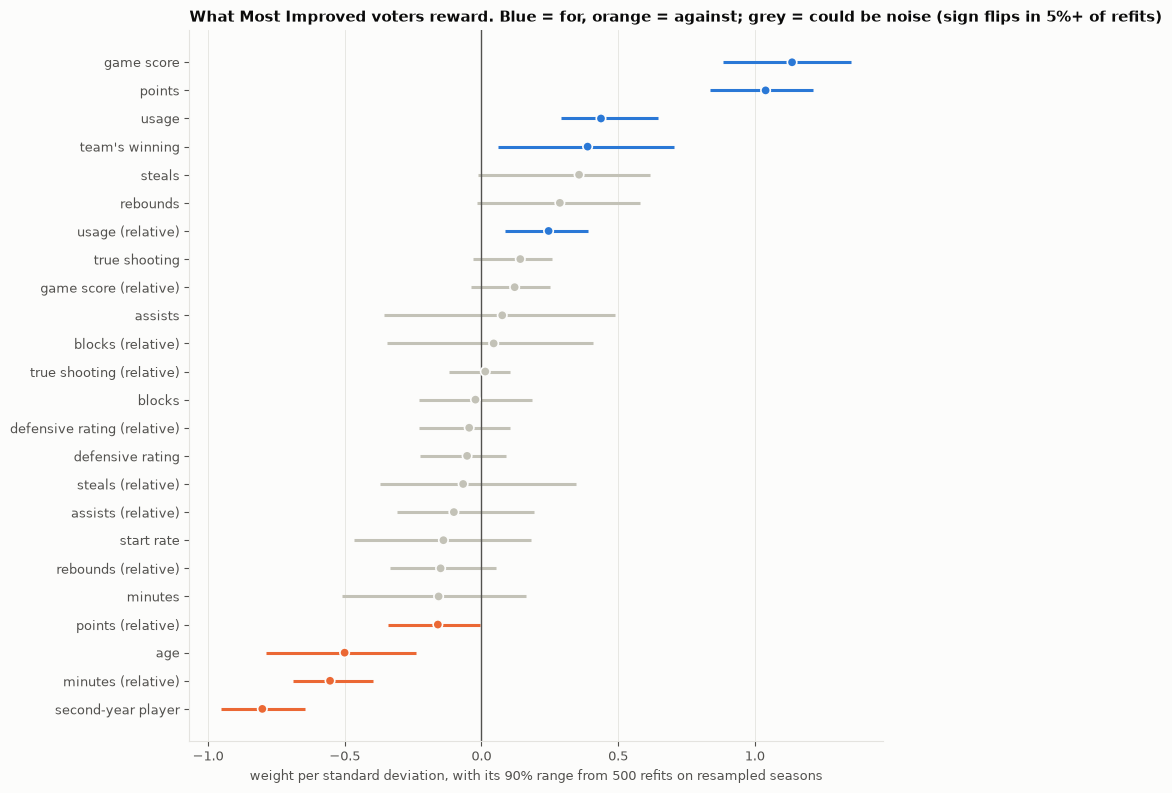

In [7]:
model = ChoiceModel(INPUTS, lam).fit(E)
boot = bootstrap_weights(E, INPUTS, lam, n_boot=500)
NICE = {"ppg_delta": "points", "rpg_delta": "rebounds", "apg_delta": "assists", "spg_delta": "steals", "bpg_delta": "blocks", "mpg_delta": "minutes",
        "game_score_delta": "game score", "ts_delta": "true shooting", "usg_delta": "usage", "start_rate_delta": "start rate",
        "def_rating_delta": "defensive rating", "team_win_delta": "team's winning", "age": "age", "second_year": "second-year player"}
NICE.update({f"{k.split('_delta')[0]}_rel": f"{v} (relative)" for k, v in NICE.items() if k.endswith("_delta") and k != "team_win_delta"})
wts = pd.DataFrame({"input": [NICE.get(c, c) for c in INPUTS], "weight per SD": model.coef_,
                    "odds × per +1 SD": np.exp(model.coef_), "same sign in refits": (np.sign(boot) == np.sign(model.coef_)).mean(axis=0),
                    "low": np.percentile(boot, 5, axis=0), "high": np.percentile(boot, 95, axis=0)}, index=INPUTS).sort_values("weight per SD")
solid = wts["same sign in refits"] >= 0.95
fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(wts))
col = np.where(wts["weight per SD"] > 0, BLUE, ORANGE)
ax.hlines(y, wts["low"], wts["high"], color=np.where(solid, col, MUTED), linewidth=2.2)
ax.scatter(wts["weight per SD"], y, s=46, color=np.where(solid, col, MUTED), edgecolor=SURFACE, linewidth=1.2, zorder=3)
ax.axvline(0, color=INK2, linewidth=1); ax.grid(axis="y", visible=False)
ax.set_yticks(y, wts["input"], fontsize=9)
ax.set_xlabel("weight per standard deviation, with its 90% range from 500 refits on resampled seasons")
ax.set_title("What Most Improved voters reward. Blue = for, orange = against; grey = could be noise (sign flips in 5%+ of refits)", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "1_what_voters_reward.png", dpi=150, bbox_inches="tight")
wts[solid].set_index("input")[["weight per SD", "odds × per +1 SD", "same sign in refits"]].round(2)

In [8]:
# in natural units: how much the odds move for a step a reader can picture
STEP = {"game_score_delta": (1, "+1 game score a game"), "ppg_delta": (1, "+1 point a game"), "usg_delta": (0.02, "+2 points of usage"),
        "team_win_delta": (0.10, "his team wins 10% more of its games"), "age": (1, "one year older"), "second_year": (1, "a second-year player")}
pd.DataFrame({"step": [s for _, s in STEP.values()],
              "odds ×": [np.exp(model.coef_[INPUTS.index(c)] / model.std_[INPUTS.index(c)] * k) for c, (k, _) in STEP.items()]},
             index=[NICE[c] for c in STEP]).round(2)

,step,odds ×
game score,+1 game score a game,1.57
points,+1 point a game,1.39
usage,+2 points of usage,1.39
team's winning,his team wins 10% more of its games,1.28
age,one year older,0.88
second-year player,a second-year player,0.08


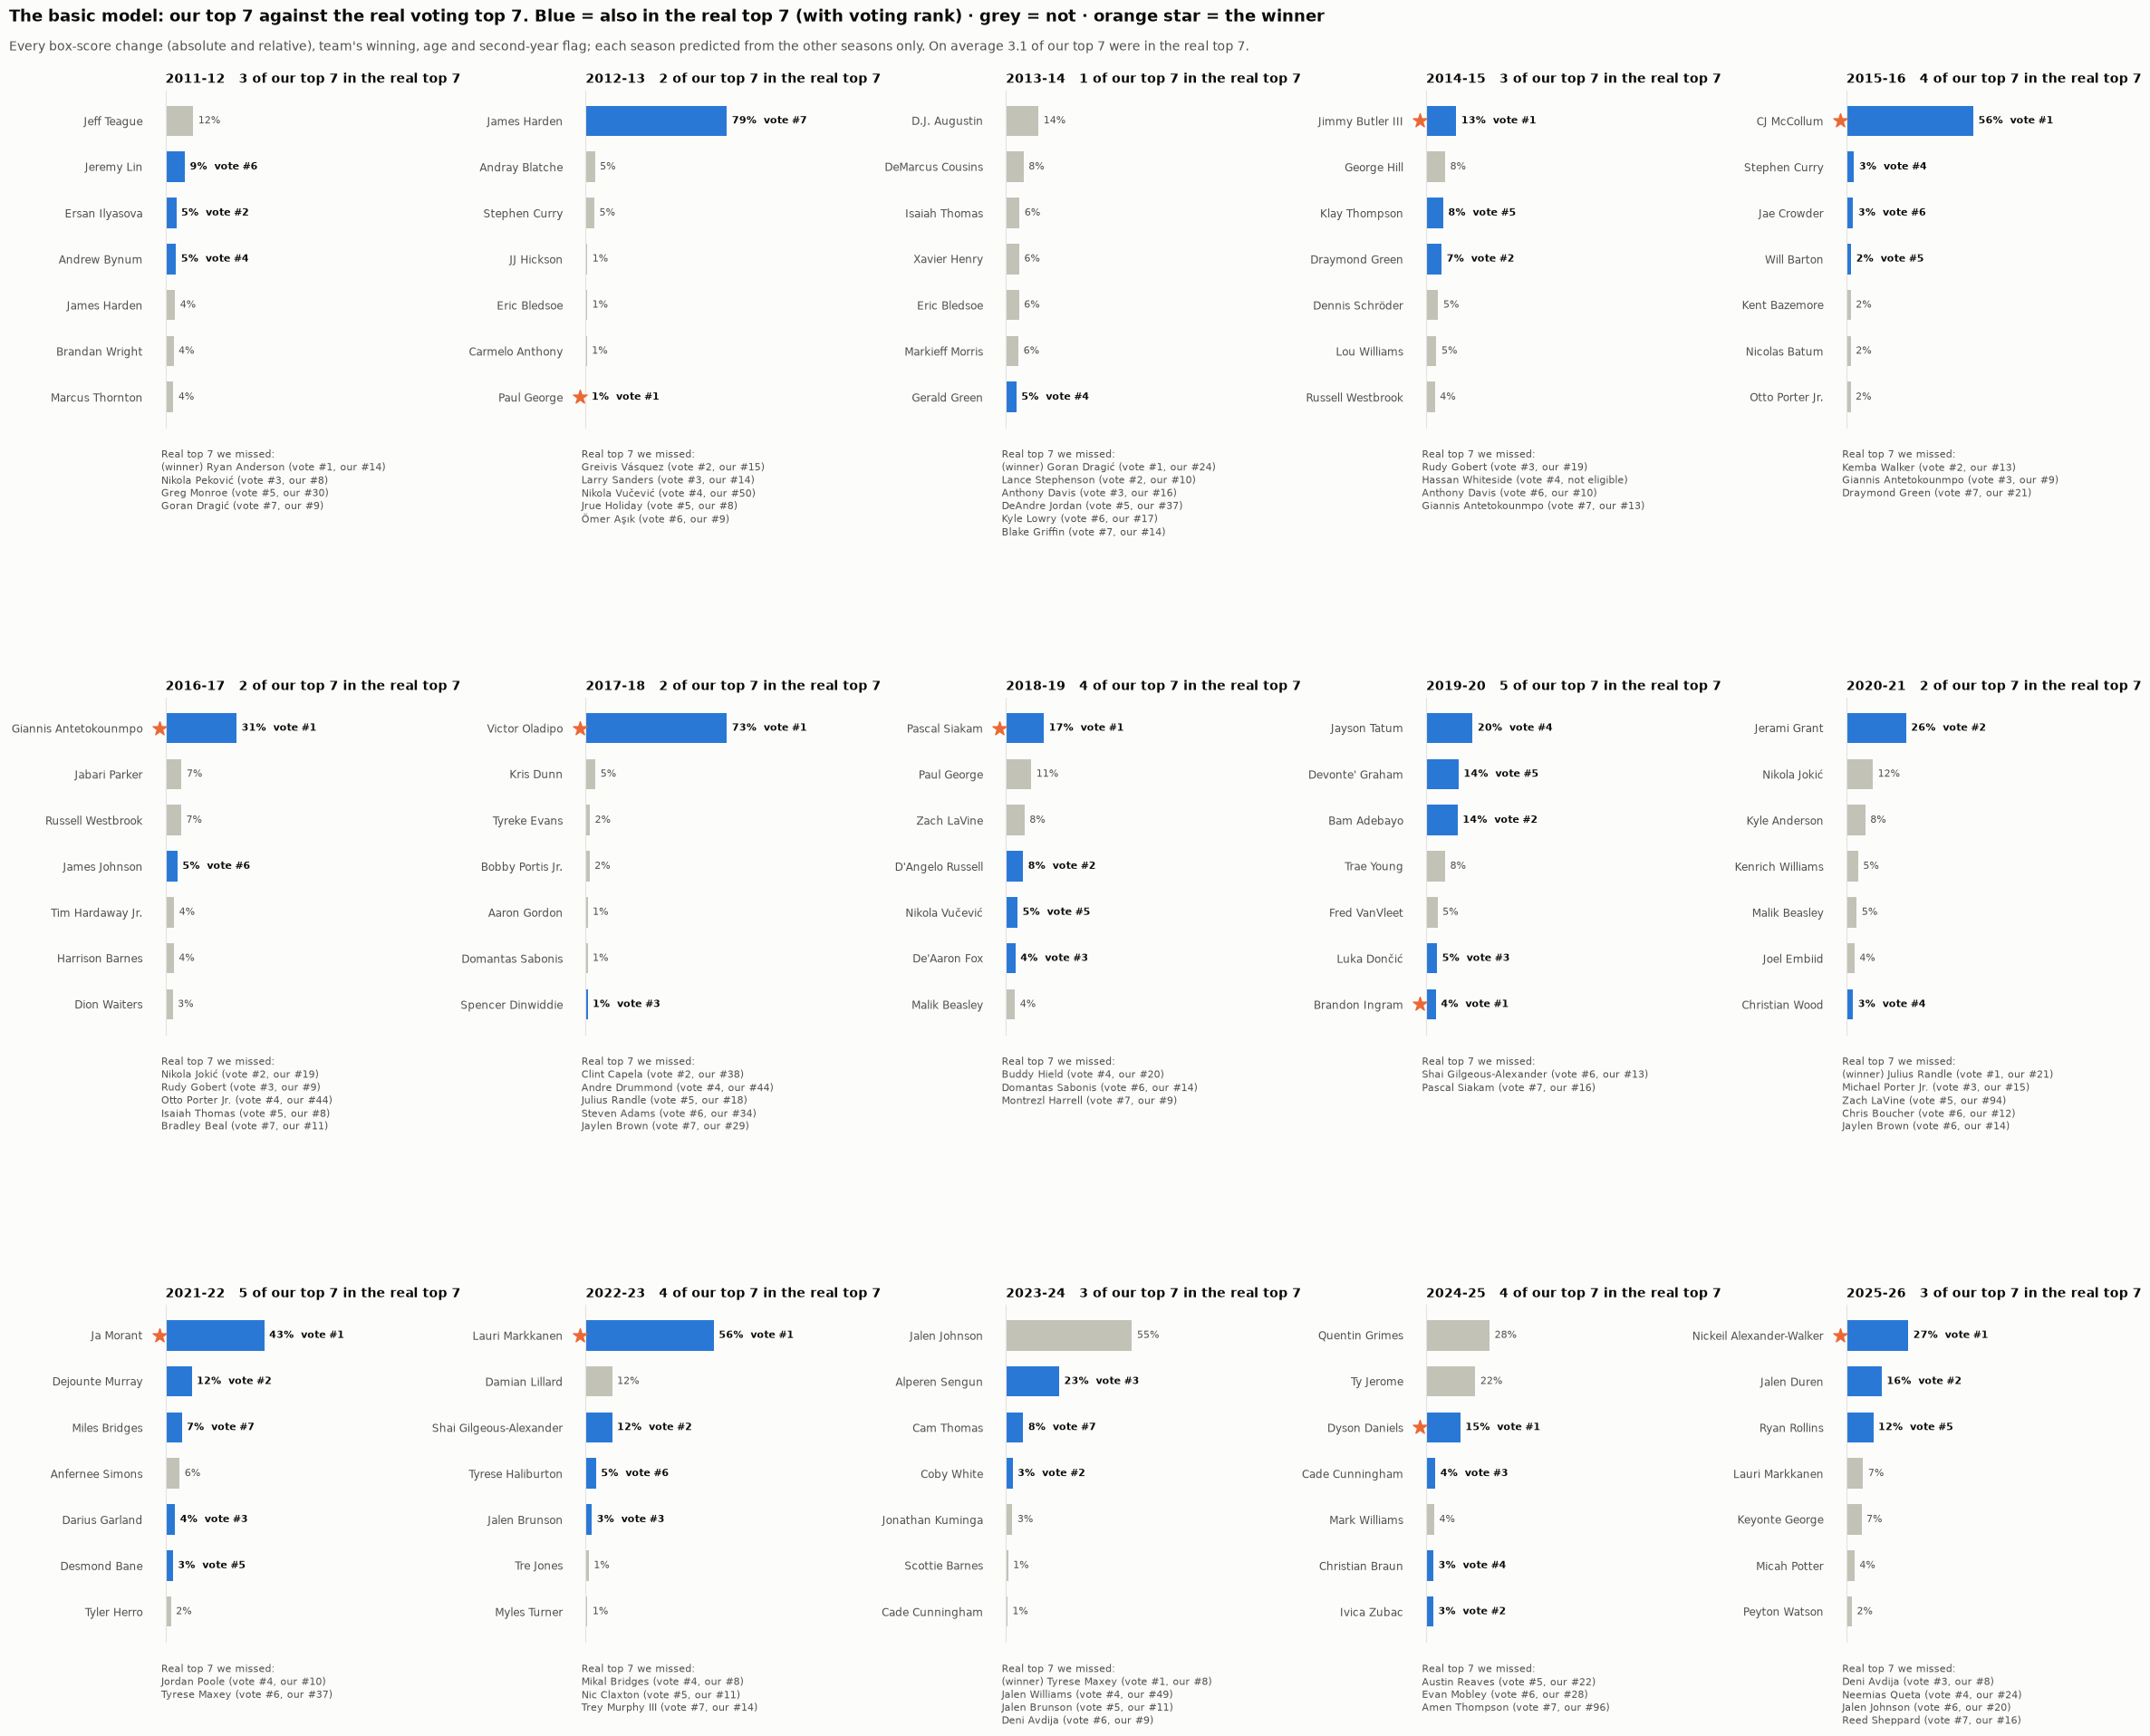

In [9]:
P = E.assign(p=p_loo)
top7_vs_votes_chart(P, votes, pool,
    "The basic model: our top 7 against the real voting top 7. Blue = also in the real top 7 (with voting rank) · grey = not · orange star = the winner",
    "Every box-score change (absolute and relative), team's winning, age and second-year flag; each season predicted from the other seasons only. "
    "On average {avg:.1f} of our top 7 were in the real top 7.",
    FIG_DIR / "1_top7_vs_real_vote.png");

## 1E — The misses: milestones and narrative

The model measures how **big** a jump was. Some winners had moderate jumps that mattered more for **who they became**. Three milestones: a first 20-point season, becoming the team's leading scorer, and a first season in our star tier (the top 10% by star score). How often do winners cross them, compared with everyone else?

In [10]:
wins = E[E["mip"]]
ms = pd.DataFrame({m: {"winners": wins[m].mean(), "all candidates": E[m].mean()} for m in MILESTONES + SECOND_YEAR}).T
ms["times more common among winners"] = ms["winners"] / ms["all candidates"]
ms.index = ["first 20-point season", "became the team's leading scorer", "first star-tier season", "second-year player"]
display(ms.style.format({"winners": "{:.0%}", "all candidates": "{:.1%}", "times more common among winners": "{:.1f}"}))
P["rank"] = P.groupby("season")["p"].rank(ascending=False, method="min").astype(int)
missed = P[P["mip"] & (P["rank"] > 3)].sort_values("rank", ascending=False)
pd.DataFrame({"winner": missed["player_name"].values, "season": missed["season"].values, "our rank": missed["rank"].values,
              "points": [f"{a:.1f} → {b:.1f}" for a, b in zip(missed["base_ppg"], missed["ppg"])],
              "first 20-point season": missed["first_20ppg"].astype(bool).values, "became leading scorer": missed["became_top_option"].astype(bool).values,
              "first star-tier season": missed["first_star_tier"].astype(bool).values})

,winners,all candidates,times more common among winners
first 20-point season,60%,2.3%,26.7
became the team's leading scorer,47%,4.4%,10.5
first star-tier season,40%,1.9%,21.2
second-year player,0%,11.5%,0.0


,winner,season,our rank,points,first 20-point season,became leading scorer,first star-tier season
0,Goran Dragic,2013-14,24,14.7 → 20.3,True,False,False
1,Julius Randle,2020-21,21,19.5 → 24.1,False,False,True
2,Ryan Anderson,2011-12,14,10.6 → 16.1,False,False,False
3,Tyrese Maxey,2023-24,8,20.3 → 25.9,False,True,False
4,Paul George,2012-13,7,12.1 → 17.4,False,True,True
5,Brandon Ingram,2019-20,7,18.3 → 23.8,True,True,False


## Findings (13 November 2026)

**How winners' seasons unfold (1A, 1B)**
- **Most leaps are there early, with a new role.** 9 of 15 winners had 80% or more of their season's leap in their first 10 games, and Giannis Antetokounmpo (78%) and Dyson Daniels (79%) were just short. The role usually came from opening night: CJ McCollum went from 15.7 to 34.7 minutes, Daniels from 22.3 to 33.0. *Correction:* notebook 10 and the README said 11 of 15, counting the two at 78–79%.
- **Some grew into it:** Paul George and Goran Dragić started at their baseline and climbed; Pascal Siakam and Nickeil Alexander-Walker had about half their leap early. The All-Star break rarely changed much; Alexander-Walker rose most after it (+3.7 game score).
- **One huge night says little.** After 1,089 "eruptions", the next 7 games averaged +3.4 game score above baseline, against +3.1 in the 7 before: the big night confirms form that was already there. From below baseline, the next 7 averaged only +1.0 (Malachi Flynn's 50 points was that case).
- **Trust the season so far.** A single game correlates about 0.3 with the rest of the season; the last 7 games about 0.56–0.58; the season so far reaches 0.63 by game 15 and 0.68 by game 25.

**The race (1C, 1D)**
- **The biggest points jump alone names the winner 4 times in 15** (top 3 in 6). It often picks a bench player handed minutes (Jeremy Lin, Tony Wroten, Solomon Hill, Guerschon Yabusele) or a star on a new team (James Harden).
- **The basic model does much better.** Leave-one-out: the winner is #1 in 8 of 15 seasons, top 3 in 9, median rank 1. Strict: #1 in 5 of 10, top 3 in 6. On average 3.1 of our top 7 were in the real voting top 7.
- **What voters reward** (the nine weights with the same sign in 95%+ of refits): a jump in game score (odds ×1.57 per extra game score a game) and in points (×1.39 per point), more usage (×1.39 per 2 points), and a team that wins more (×1.28 per 10% more wins). **Against:** age (×0.88 per year), a jump that comes from more minutes, and above all being a second-year player (×0.08): 11.5% of candidates, 0 of 15 winners.

**The misses (1E)**
- **Winners cross milestones far more often than other candidates:** a first 20-point season (60% against 2.3%), a first star-tier season (40% against 1.9%), becoming the team's leading scorer (47% against 4.4%).
- **The model's biggest misses are exactly those:** Dragić (24th; first 20-point season), Julius Randle (21st; first star-tier season), Tyrese Maxey (8th) and Paul George (7th; both became their team's leading scorer). Their jumps were moderate but changed who they were, and the rest is narrative in crowded years (Dragić's and Randle's teams improved sharply; notebook 10I).
- **Where this goes next:** segment 3 investigates the cases the race raised; segment 4 refines this model one tested decision at a time.